In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show one value per region on the dorsal cortex flat map

This example walks through various ways to overlay brain region values on a cortical flatmap

## The dorsal cortex flatmap

The **dorsal_cortex** flatmap comprises a flattened volume of cortex up to depth 2000 um

<Axes: >

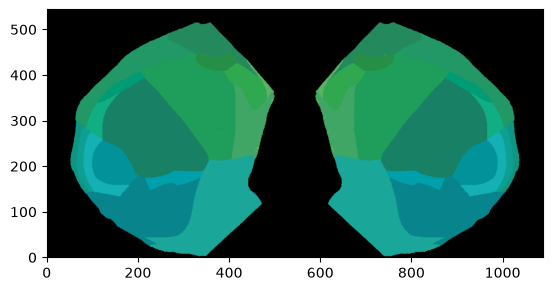

In [2]:
from iblatlas.flatmaps import FlatMap

res = 25
flmap = FlatMap(flatmap='dorsal_cortex', res_um=res)

# Plot flatmap at depth = 0 
flmap.plot_flatmap(int(0 / res))

<Axes: >

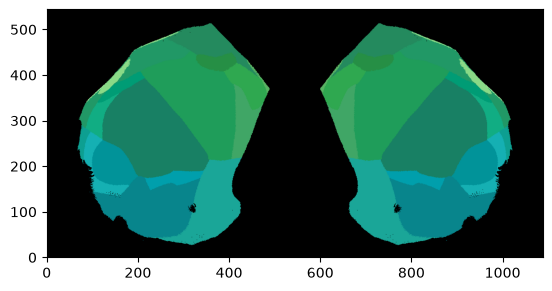

In [3]:
# Plot flatmap at depth = 800 um
flmap.plot_flatmap(int(800 / res))

## Examples

The examples use stand-in values, one for each Beryl region; replace `acronyms` and `values` with your own. For the input the plotting functions take, see [Show one value per region: choose a view](show-one-value-per-region.ipynb).

In [4]:
import numpy as np

from iblatlas.regions import BrainRegions

br = BrainRegions()

# Stand-in values: one per Beryl region
acronyms = br.acronym[np.unique(br.mappings['Beryl'])]
acronyms = acronyms[~np.isin(acronyms, ['void', 'root'])]
values = np.random.default_rng(0).random(acronyms.size)

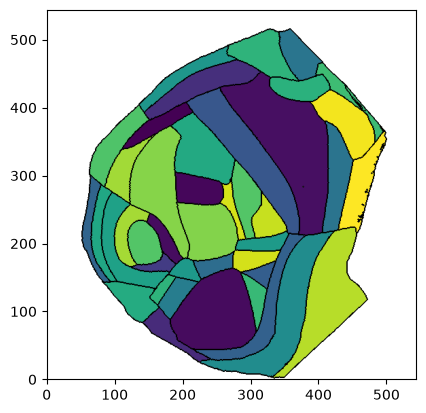

In [5]:
from iblatlas.plots import plot_scalar_on_flatmap

# Plot region values on the left hemisphere at depth=0um overlaid on boundary image
fig, ax = plot_scalar_on_flatmap(acronyms, values, depth=0, mapping='Beryl', hemisphere='left', background='boundary',
                                cmap='viridis', flmap_atlas=flmap)

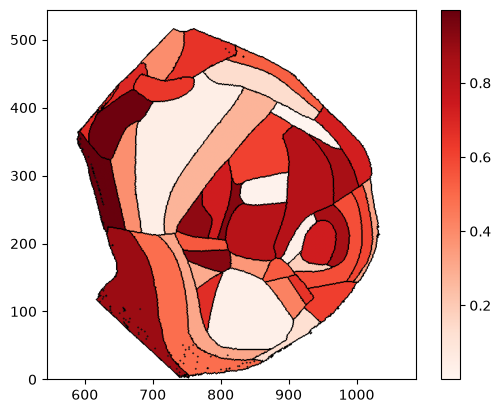

In [6]:
# Plot region values on the right hemisphere at depth=200um overlaid on boundary image and show cbar
fig, ax, cbar = plot_scalar_on_flatmap(acronyms, values, depth=200, mapping='Beryl', hemisphere='right', background='boundary',
                                cmap='Reds', flmap_atlas=flmap, show_cbar=True)

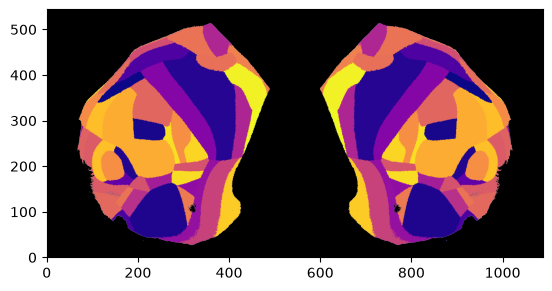

In [7]:
# Plot single column region values on both hemispheres at depth=800um overlaid dwi Allen image
fig, ax = plot_scalar_on_flatmap(acronyms, values, depth=800, mapping='Beryl', hemisphere='both',
                                 background='image', cmap='plasma', flmap_atlas=flmap)

To show different values in each hemisphere, see [Show different values in each hemisphere](show-different-values-in-each-hemisphere.ipynb).